<a href="https://colab.research.google.com/github/Zeen177/DA201-Workbooks/blob/main/da201_lesson_11_avl_trees_Zeen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 11 Workbook — AVL Trees

Keeping a search tree balanced, one rotation at a time.

| Section | Points |
|---|---|
| 1. In Your Own Words | 25 |
| 2. Trace by Hand | 20 |
| 3. Core Implementation | 20 |
| 4. Evaluate the AI | 20 |
| 5. Reflection | 15 |

Write each response in the answer cell beneath the question.


---
## Section 1 — In Your Own Words  (25 points)

No code. Answer in your own words; do not paste definitions.


### 1.1 — Why plain BSTs fail
- Insert `1, 2, 3, 4, 5` into an unbalanced BST. Describe the shape without drawing it.
- What is the search cost, and what structure has the tree effectively become?


**Your answer — 1.1 — Why plain BSTs fail**

Right-skewed line or Right-leaning line. Every node only has a right child,extending downward to the tight

Search cost: O$(n)$

Effective structure: Linked list


### 1.2 — Balance factor
- Define a node's balance factor. Use this course's convention: the height of the right subtree minus the height of the left.
- What range of values counts as balanced, and what does a value outside it mean?


**Your answer — 1.2 — Balance factor**

Balance factor: $b = height(right) - height(left)$

Balance Range: $(-1, 0, +1)$

Meaning outside range: The node is broken

### 1.3 — The null height convention
- This implementation gives a null node height `-1` rather than `0`. Explain what that makes come out right.
- What would break if you used `0` instead?


**Your answer — 1.3 — The null height convention**

What null = -1 makes come out right

A leaf node has no children (both are null). The formula $1 + \max(-1, -1) = 0$ correctly gives a leaf height of 0

Single-child node height = 1

For a node with one leaf child (height 0) and one null, the formula $1 + \max(0, -1) = 1$ correctly gives height 1.

All nodes can use the exact same code without extra special logic.

What would break if using 0 instead

A leaf node wrongly gets a height of 1 instead of 0.

A leaf node and a single-child node end up with the same height.

The balance factor calculation gets wrong values, breaking the AVL tree balance decision.

---
## Section 2 — Trace by Hand  (20 points)

Write your prediction **before** running anything. The prediction is what is graded.


### 2.1 — Label a whole tree

The tree below is an ordinary binary search tree. It is **not** an AVL tree.

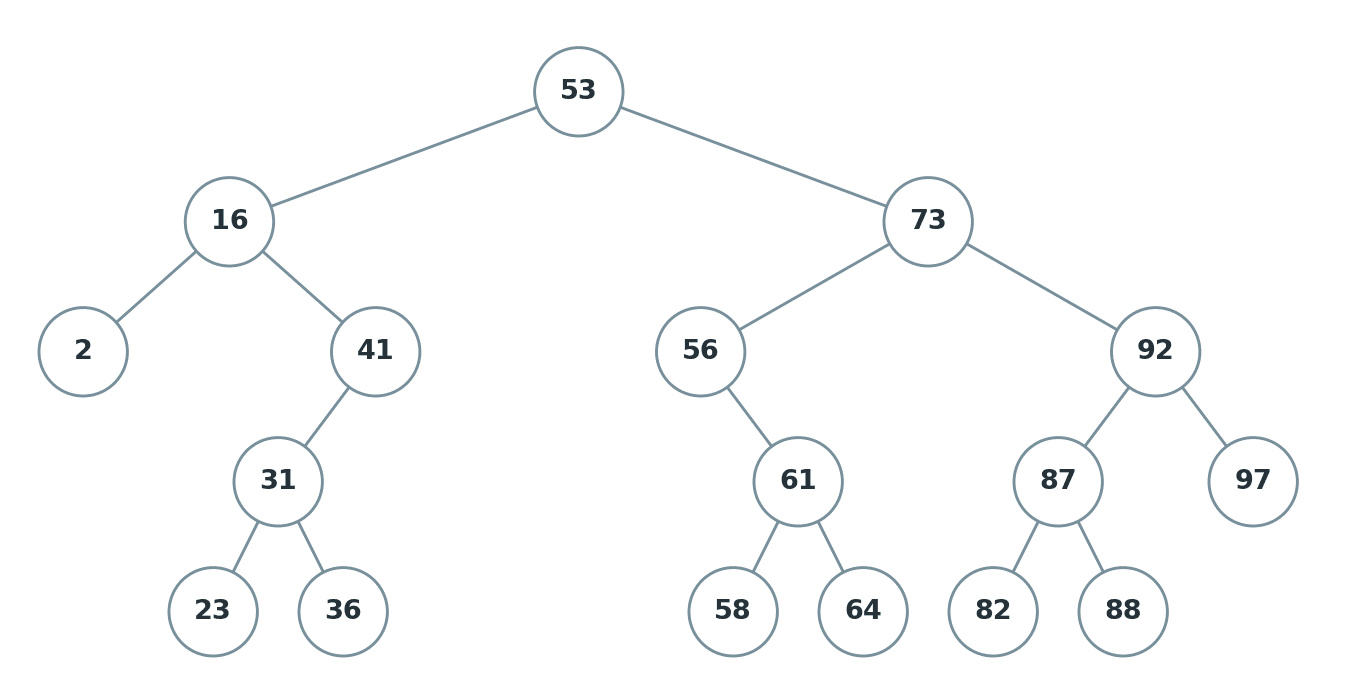

*If the image does not render: this is the plain BST (no rebalancing) produced by inserting
`53, 16, 73, 2, 41, 56, 92, 31, 61, 87, 97, 23, 36, 58, 64, 82, 88` in that order.*

Redraw the tree — a photo of a clear hand drawing is fine — and then:

- Write the **height** next to every one of the 17 nodes. A null child has height `-1`.
- Write the **balance factor** next to every node, using `b = height(right) - height(left)`.
- List every node whose balance factor is outside `-1, 0, +1`, and name the case (LL, LR, RR, or RL) at each one.
- The root's balance factor is `0`. Explain why that does not make the tree balanced.
- If you were repairing this tree, which node would you rotate about **first**? Say why that one rather than another.


**Your answer — 2.1 — Label a whole tree**

(Formula: $\text{height} = 1 + \max(\text{left}, \text{right})$, $b = \text{height(right)} - \text{height(left)}$, $\text{null} = -1$)

Node2: h = 0, b = 0

Node16: h = 3, b = +2 (Broken)

Node23: h = 0, b = 0

Node 31: h = 1, b = 0

Node36: h = 0, b = 0

Node41: h = 2, b = -2 (Broken)

Node53: h = 4, b = 0

Node56: h = 2, b = +2 (Broken)

Node58: h = 0, b = 0

Node61: h = 1, b = 0

Node64: h = 0, b = 0

Node73: h = 3, b = 0

Node82: h = 0, b = 0

Node87: h = 1, b = 0

Node88: h = 0, b = 0

Node92: h = 2, b = -1

Node97: h = 0, b = 0

Nodes outside $\{-1, 0, +1\}$ and their CasesNode

41 ($b = -2$, left child $b = 0$): LL Case

Node 16 ($b = +2$, right child $b = -2$): RL Case

Node 56 ($b = +2$, right child $b = 0$): RR Case

The root's balance factor $b = 0$ only means its left and right subtrees have the same height. However, the AVL rule requires every node in the tree to have |b|≤1. A single 0 at the root cannot see broken nodes deeper down.

Which node to rotate about first

Rotate about Node 41 first. Repairs must start at the lowest broken node. Fixing a deeper node restores its subtree height, which updates ancestor balance factors and may fix upper imbalances automatically.

### 2.2 — Naming the case
For each insertion sequence, name the imbalance case (LL, LR, RR, or RL) and the rotation(s) required:

- `30, 20, 10`
- `30, 10, 20`
- `10, 20, 30`
- `10, 30, 20`


**Your answer — 2.2 — Naming the case**

30, 20, 10

Case: LL Case

Rotation(s): One right rotation at node 30

30, 10, 20

Case: LR Case

Rotation(s): Two rotations — Left rotation at child 10, then right rotation at node 30

10, 20, 30

Case: RR Case

Rotation(s): One left rotation at node 10

10, 30, 20

Case: RL Case

Rotation(s): Two rotations — Right rotation at child 30, then left rotation at node 10

### 2.3 — A double rotation
Insert `50, 30, 40` into an empty AVL tree.

- Draw the tree after each insertion, with heights and balance factors.
- Identify the first node that goes out of balance.
- Show the tree after each of the two rotations, not just the final result.


**Your answer — 2.3 — A double rotation**

     50 (h=2, b=-2)
      /
    30 (h=1, b=+1)
      \
      40 (h=0, b=0)

Identify the first node out of balance

Node 50 is the first node that goes out of balance ($b = -2$).

    Rotation 1:
     50 (h=2, b=-2)
      /
    40 (h=1, b=-1)
     /
    30 (h=0, b=0)

    
    Rotation 2
    40 (h=1, b=0)
    /            \
    30 (h=0, b=0) 50 (h=0, b=0)

### 2.4 — What must be recomputed
- After a rotation, which nodes' heights are now stale?
- In what order must they be recomputed, and why does the order matter?


**Your answer — 2.4 — What must be recomputed**

Which nodes' heights are now stale?

The node that moved down and the node that moved up

In what order must they be recomputed

Bottom-up. Update the lower node first, then the higher node second



---
## Section 3 — Core Implementation  (20 points)

Implement `height`, `balanceFactor`, `rotateLeft`, and `rotateRight` in `avl.tpp`. Get these four right in isolation — `insert` depends entirely on them.


In [8]:
%%writefile avl.h
#pragma once
#include <iostream>
#include <algorithm>

template <typename K, typename V>
class AVL {
private:
    struct Node {
        K key; V value;
        Node* left; Node* right;
        int height;
        Node(const K& k, const V& v) : key(k), value(v), left(nullptr), right(nullptr), height(0) {}
    };
    Node* root;
    int height(Node* curr) const;
    int balanceFactor(Node* curr) const;
    void updateHeight(Node* curr);
    Node* rotateLeft(Node* curr);
    Node* rotateRight(Node* curr);
    void destroy(Node* curr);
public:
    AVL();
    ~AVL();
};

#include "avl.tpp"


Overwriting avl.h


In [9]:
%%writefile avl.tpp

template <typename K, typename V>
AVL<K,V>::AVL() : root(nullptr) {}

template <typename K, typename V>
AVL<K,V>::~AVL() {
    destroy(root);
}

template <typename K, typename V>
void AVL<K,V>::destroy(Node* curr) {
    if (!curr) return;
    destroy(curr->left);
    destroy(curr->right);
    delete curr;
}

template <typename K, typename V>
int AVL<K,V>::height(Node* curr) const {
    return curr == nullptr ? -1 : curr->height;
}

template <typename K, typename V>
int AVL<K,V>::balanceFactor(Node* curr) const {
    return height(curr->right) - height(curr->left);
}

template <typename K, typename V>
void AVL<K,V>::updateHeight(Node* curr) {
    if (curr != nullptr) {
        curr->height = 1 + std::max(height(curr->left), height(curr->right));
    }
}

template <typename K, typename V>
typename AVL<K,V>::Node* AVL<K,V>::rotateLeft(Node* curr) {
    Node* r = curr->right;
    curr->right = r->left;
    r->left = curr;

    updateHeight(curr);
    updateHeight(r);

    return r;
}

template <typename K, typename V>
typename AVL<K,V>::Node* AVL<K,V>::rotateRight(Node* curr) {
    Node* l = curr->left;
    curr->left = l->right;
    l->right = curr;

    updateHeight(curr);
    updateHeight(l);

    return l;
}


Overwriting avl.tpp


In [10]:
%%writefile main.cpp
#include "avl.h"
#include <iostream>
using namespace std;

int main() {
    cout << "AVL Tree rotation code compiled successfully!" << endl;
    return 0;
}

Overwriting main.cpp


In [11]:
!g++ main.cpp -o avl_test
!./avl_test


AVL Tree rotation code compiled successfully!


---
## Section 4 — Evaluate the AI  (20 points)

A student asked an AI for the left rotation. It returned this.

> **AI:** "Standard left rotation. Heights are refreshed and the new root is returned. Rotation is O(log n) because it walks down the tree."

It compiles and returns a tree that still looks like a tree. There are **three** problems.


In [12]:
// AI-generated rotateLeft() — do not trust it
template <typename K, typename V>
typename AVL<K,V>::Node* AVL<K,V>::rotateLeft(Node* curr) {
    Node* r = curr->right;

    updateHeight(curr);
    updateHeight(r);

    curr->right = r->left;
    r->left = curr;

    return r;
}


SyntaxError: invalid character '—' (U+2014) (1118301224.py, line 1)

### Diagnose
- The heights are updated, but they end up wrong. Explain exactly why — what changed after `updateHeight` ran?
- Give the correct ordering of the four statements, and say which node's height must be updated **last**.
- The AI called rotation O(log n). Give the correct complexity and justify it in one sentence.

### Show it
Take a three-node right-heavy subtree with known heights. Trace the AI's version and show the incorrect height it produces. Then trace your corrected version and show the right one.

### Fix
Rewrite `rotateLeft` correctly.


**Your answer — Section 4 — diagnosis, fixes, and your judgment of the AI**

Diagnose

Why heights end up wrong: updateHeight() ran before pointer re-linking, so curr calculated its height using its old child r. After the pointers moved, curr became a leaf but kept that old, wrong height.

Correct ordering:

curr->right = r->left;

r->left = curr;

updateHeight(curr);

updateHeight(r);

Node r (the new root) must be updated last because its height depends on curr.

Show it

For a right-heavy subtree with nodes

AI's Version:updateHeight(curr) measures 10 while it still has 20 below it, storing height 2.

updateHeight(r) measures 20 with child 30, storing height 1.

Pointers re-link, making 10 a leaf, but 10 still wrongly stores height 2 (true height is 0).

Corrected Version:

Pointers re-link first.

updateHeight(curr) measures leaf 10 with no children, storing height 0.

updateHeight(r) measures 20 with children 10 (height 0) and 30 (height 0), storing height 1

In [ ]:
%%writefile avl.tpp
template <typename K, typename V>
typename AVL<K,V>::Node* AVL<K,V>::rotateLeft(Node* curr) {
    Node* r = curr->right;

    curr->right = r->left;
    r->left = curr;

    updateHeight(curr);
    updateHeight(r);

    return r;
}

---
## Section 5 — Reflection  (15 points)


### 5.1
A stale height does not crash anything — it silently misleads every later balance check. How would you catch a bug like that?

### 5.2
Lesson 12 builds removal on top of these rotations. What will you verify before you start?


**Your answer — Section 5 — Reflection**

5.1 Assert actual height: Write a recursive function to compute thure height and run

Unit test rotations: Test rotateLeft and rotateRight on a 3-node subtree and check node heights directly.

5.2 Helper functions: Ensure height(nullptr) == -1, balanceFactor

Rotation logic: Ensure rotateLeft and rotateRight re-link pointers first and update heights bottom-up.

Insertion rebalancing: Ensure insert() handles all 4 imbalance cases (LL, LR, RR, RL) correctly.

---
## Submission

1. Confirm you are working in your renamed copy, not the shared original.
2. Share your copy with **kkoe@taejae.ac.kr** with at least Viewer access.
3. Paste the shareable Google Drive link into the Workbook — Lesson 11 assignment on Canvas.
